# configuration & loadings

In [15]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.inspection import permutation_importance

plt.style.use("default")

In [16]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "gvns").exists():
    PROJECT_ROOT = Path(__file__).parent.parent.parent.parent if '__file__' in locals() else Path.cwd().parent.parent.parent

print(f"Project root: {PROJECT_ROOT}")

Project root: c:\Users\HP\Documents\GitHub\GVNS-implementation


In [29]:
DATA_PATH = PROJECT_ROOT / "gvns" / "ls_data" / "learning_dataset.csv"
MODEL_PATH = PROJECT_ROOT / "gvns" / "ml" / "models" / "rf_delta_regressor.pkl"
FEATURES_PATH = PROJECT_ROOT / "gvns" / "ml" / "models" / "rf_features.json"

# Load artifacts
df = pd.read_csv(DATA_PATH)
model = joblib.load(MODEL_PATH)

with open(FEATURES_PATH, "r") as f:
    feature_names = json.load(f)

print(f"Dataset shape: {df.shape}")
print(f"Number of features: {len(feature_names)}")

Dataset shape: (22642, 29)
Number of features: 26


# importance

In [30]:
# prepare X and y
y = df["rel_delta"]

# Features
X = df[feature_names]

# Sanity check
assert X.shape[1] == len(feature_names)

## built-in RF importance

In [31]:
importances = pd.Series(
    model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

importances.head(15)

max_delta_W           0.199500
avg_delta_W           0.193331
improv_rate_W         0.091971
ls_fail_ratio_W       0.080029
penT_ratio            0.057847
pen_ratio             0.054052
elapsed               0.037956
PV                    0.037377
time_elapsed_ratio    0.032151
strategy              0.027730
time_left_ratio       0.027089
n_customers           0.022730
early_tw_ratio        0.020840
n_vehicles            0.019239
avg_tw_width          0.015930
dtype: float64

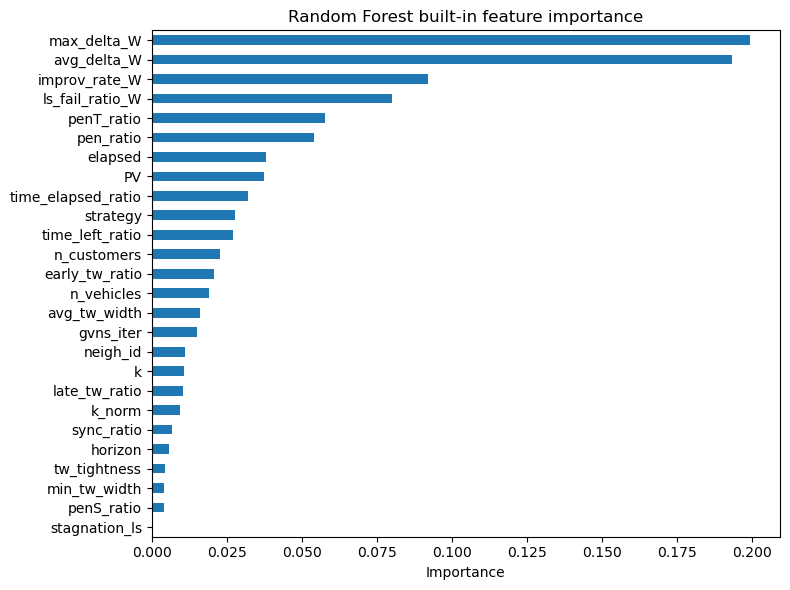

In [33]:
top_n = 20

plt.figure(figsize=(8, 6))
importances.iloc[::-1].plot(kind="barh")
plt.title("Random Forest built-in feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## permutation importance 

In [34]:
perm = permutation_importance(
    model,
    X,
    y,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
    scoring="neg_mean_squared_error"
)

perm_importance = pd.Series(
    perm.importances_mean,
    index=feature_names
).sort_values(ascending=False)

perm_importance

max_delta_W           0.000403
avg_delta_W           0.000351
improv_rate_W         0.000170
ls_fail_ratio_W       0.000142
penT_ratio            0.000118
pen_ratio             0.000116
PV                    0.000101
elapsed               0.000068
n_customers           0.000066
strategy              0.000062
early_tw_ratio        0.000057
n_vehicles            0.000053
time_elapsed_ratio    0.000052
neigh_id              0.000047
k                     0.000044
time_left_ratio       0.000041
k_norm                0.000041
avg_tw_width          0.000033
gvns_iter             0.000025
late_tw_ratio         0.000019
sync_ratio            0.000012
horizon               0.000011
min_tw_width          0.000008
tw_tightness          0.000007
penS_ratio            0.000005
stagnation_ls         0.000000
dtype: float64

In [35]:
perm_df = perm_importance.reset_index()
perm_df.columns = ["feature", "importance"]
perm_df


,feature,importance
0,max_delta_W,0.000403
1,avg_delta_W,0.000351
2,improv_rate_W,0.000170
3,ls_fail_ratio_W,0.000142
4,penT_ratio,0.000118
5,pen_ratio,0.000116
6,PV,0.000101
7,elapsed,0.000068
8,n_customers,0.000066
9,strategy,0.000062


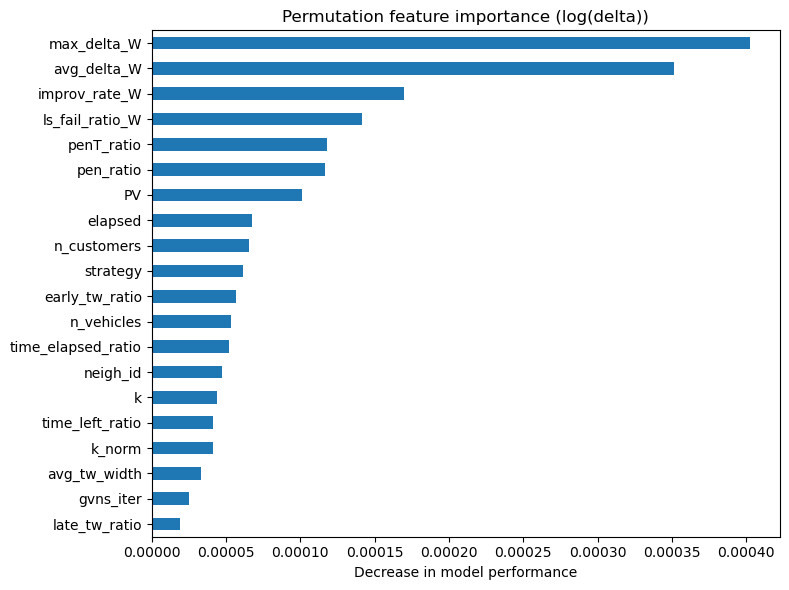

In [36]:
top_n = 20

plt.figure(figsize=(8, 6))
perm_importance.head(top_n).iloc[::-1].plot(kind="barh")
plt.title("Permutation feature importance (log(delta))")
plt.xlabel("Decrease in model performance")
plt.tight_layout()
plt.show()

### comparison 

In [37]:
comparison = pd.DataFrame({
    "rf_importance": importances,
    "perm_importance": perm_importance
}).sort_values("perm_importance", ascending=False)

comparison

,rf_importance,perm_importance
max_delta_W,0.199500,0.000403
avg_delta_W,0.193331,0.000351
improv_rate_W,0.091971,0.000170
ls_fail_ratio_W,0.080029,0.000142
penT_ratio,0.057847,0.000118
pen_ratio,0.054052,0.000116
PV,0.037377,0.000101
elapsed,0.037956,0.000068
n_customers,0.022730,0.000066
strategy,0.027730,0.000062


In [40]:
comp = comparison.reset_index()
comp.columns = ["feature", "rf_importance", "perm_importance"]
comp

,feature,rf_importance,perm_importance
0,max_delta_W,0.199500,0.000403
1,avg_delta_W,0.193331,0.000351
2,improv_rate_W,0.091971,0.000170
3,ls_fail_ratio_W,0.080029,0.000142
4,penT_ratio,0.057847,0.000118
5,pen_ratio,0.054052,0.000116
6,PV,0.037377,0.000101
7,elapsed,0.037956,0.000068
8,n_customers,0.022730,0.000066
9,strategy,0.027730,0.000062


## grouped importance 
its more "reasearch grade" 

In [38]:
FEATURE_GROUPS = {
    "search_dynamics": [
        "improv_rate_W",
        "avg_delta_W",
        "max_delta_W",
        "ls_fail_ratio_W",
        "time_left_ratio",
        "time_elapsed_ratio",
    ],
    "strategy_control": [
        "strategy",
        "k",
        "k_norm",
        "neigh_id",
    ],
    "instance_structure": [
        "tw_tightness",
        "avg_tw_width",
        "min_tw_width",
        "early_tw_ratio",
        "late_tw_ratio",
        "n_customers",
        "n_vehicles",
        "horizon",
        "sync_ratio",
    ],
    "penalties": [
        "pen_ratio",
        "penT_ratio",
        "penS_ratio",
    ],
}

group_importance = {}

for group, feats in FEATURE_GROUPS.items():
    feats = [f for f in feats if f in perm_importance]
    group_importance[group] = perm_importance[feats].sum()

grp_importance = pd.Series(group_importance).sort_values(ascending=False)
grp_importance

search_dynamics       0.001158
instance_structure    0.000265
penalties             0.000240
strategy_control      0.000193
dtype: float64

In [39]:
grp_df = grp_importance.reset_index()
grp_df.columns = ["groupe", "importance"]
grp_df

,groupe,importance
0,search_dynamics,0.001158
1,instance_structure,0.000265
2,penalties,0.000240
3,strategy_control,0.000193
